In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import scipy.stats as stats

In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

# Part 1: Analyzing Best-Seller Trends Across Product Categories

Objective: Understand the relationship between product categories and their best-seller status.

## 1. Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.

In [3]:
category_bestseller = pd.crosstab(df['category'], df['isBestSeller'])
category_bestseller

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


- Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [4]:
category_bestseller['proportion'] = category_bestseller[True] / (category_bestseller[True] + category_bestseller[False])
category_bestseller = category_bestseller.sort_values('proportion', ascending= False)
category_bestseller

isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
Bedding Collections,6309,0,0.000000
CPUs,249,0,0.000000
"CD, Disc & Tape Players",8798,0,0.000000


## 2. Statistical Tests:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [6]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(category_bestseller)

chi2_statistic, chi2_p_value

(np.float64(36684.237866368574), np.float64(0.0))

El pvalue es 0.0 por lo que no es independiente.

- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [7]:
category_bestseller_cramer = pd.crosstab(df['category'], df['isBestSeller'])
association(category_bestseller_cramer, method="cramer")

0.1222829439760564

La relación es débil, ya que el resultado es 0.12

## 3. Visualizations:

- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

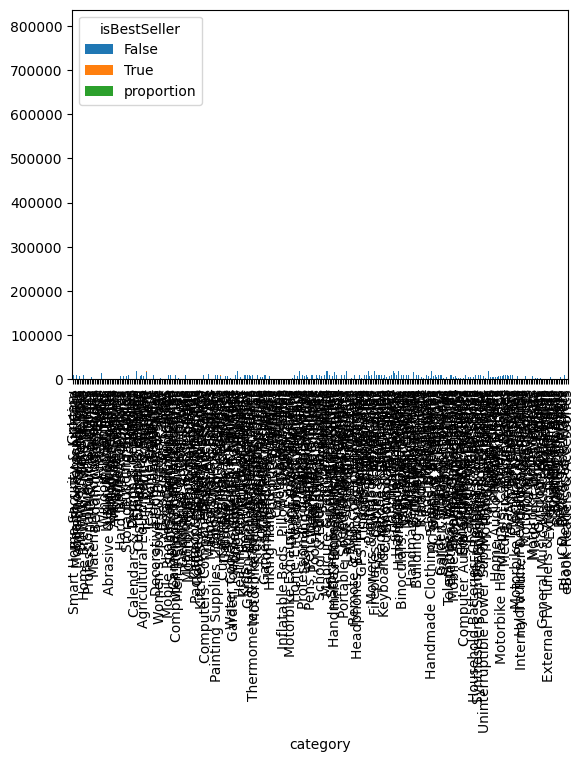

In [8]:
category_bestseller.plot(kind="bar", stacked=True)

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

## 0. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [9]:
def tukeys_test_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_clean = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    
    return df_clean

In [10]:
df_no_outliers_price = tukeys_test_outliers(df, 'price')

## 1. Violin Plots:

- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.

<Axes: xlabel='price', ylabel='category'>

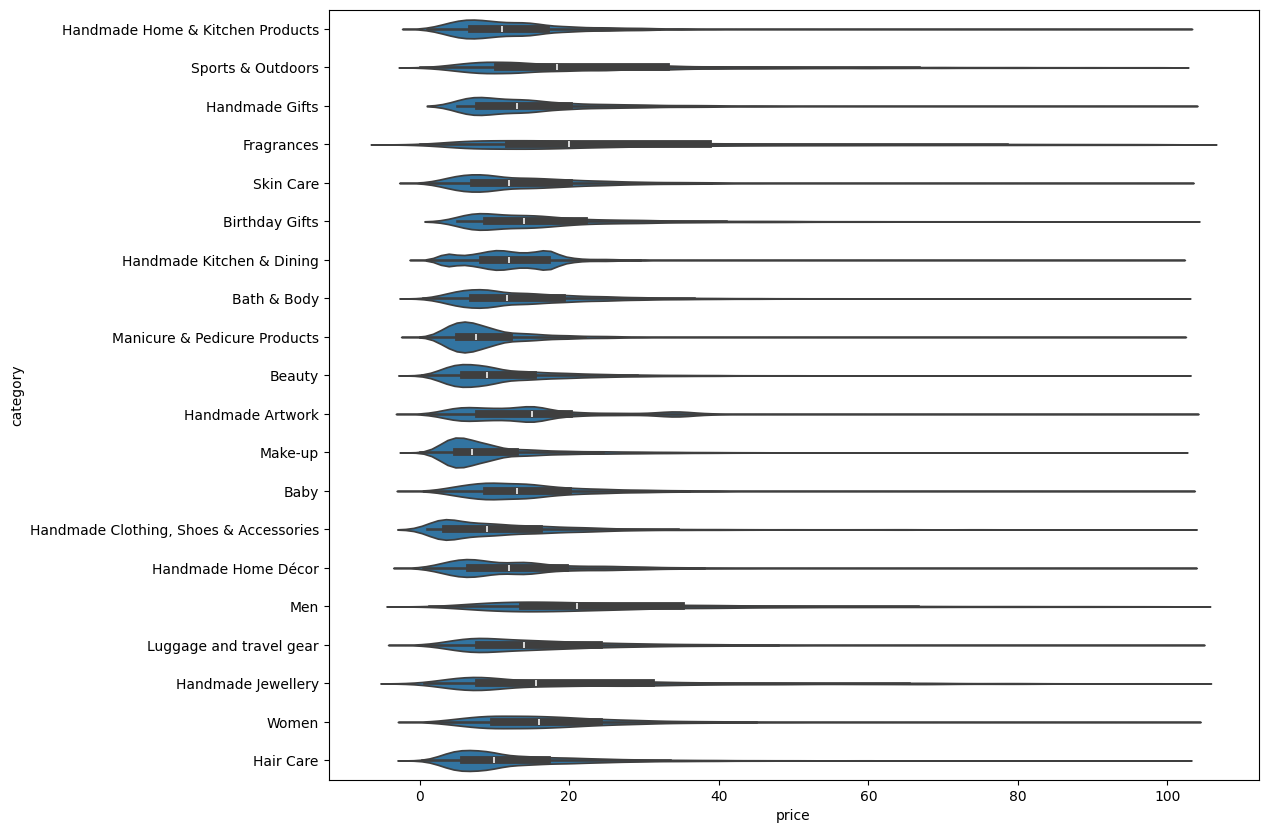

In [17]:
category_counts = df_no_outliers_price['category'].value_counts()
top_20_categories = category_counts.head(20).index
df_top20 = df_no_outliers_price[df_no_outliers_price['category'].isin(top_20_categories)]

plt.figure(figsize=(12,10))
sns.violinplot(data=df_top20, y='category', x='price')

- Which product category tends to have the highest median price? Don't filter here by top categories.

In [18]:
median_prices = df.groupby('category')['price'].median().sort_values(ascending=False).round(2)
median_prices

category
Laptops                      1042.72
Desktop PCs                   810.40
Snowboards                    366.72
Home Audio Record Players     326.08
3D Printers                   319.00
                              ...   
Adapters                        7.05
Make-up                         7.00
Signs & Plaques                 6.99
Arts & Crafts                   5.99
Office Paper Products           4.38
Name: price, Length: 296, dtype: float64

Las laptops y desktop PCs tienden a tener la medianas mas altas.

## 2. Bar Charts:

- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

In [26]:
top10_categories = df['category'].value_counts().head(10).index
avg_price_category = (df[df['category'].isin(top10_categories)].groupby('category')['price'].mean().sort_values(ascending=False))
avg_price_category.round(2)

category
Sports & Outdoors                         125.77
Fragrances                                 36.20
Birthday Gifts                             26.59
Handmade Clothing, Shoes & Accessories     16.87
Skin Care                                  16.34
Bath & Body                                15.04
Hair Care                                  14.33
Beauty                                     13.22
Make-up                                    10.90
Manicure & Pedicure Products               10.52
Name: price, dtype: float64

<Axes: xlabel='category'>

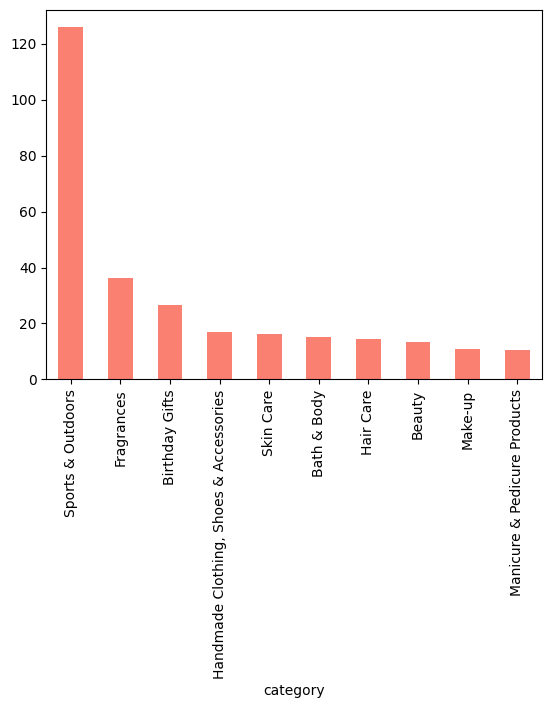

In [27]:
avg_price_category.plot(kind='bar', color='salmon')

La categoria con el precio medio mas alto de los productos mas vendidos es Sports & Outdoors

- Which product category commands the highest average price? Don't filter here by top categories.

In [28]:
avg_price_all = df.groupby('category')['price'].mean().round(2).sort_values(ascending=False)
avg_price_all

category
Laptops                  1087.99
3D Printers              1018.04
Desktop PCs               926.82
Home Office Furniture     622.14
Test & Measurement        559.38
                          ...   
Bedding Accessories         8.84
Adapters                    8.75
Signs & Plaques             8.28
Arts & Crafts               8.18
Office Paper Products       7.05
Name: price, Length: 296, dtype: float64

Laptops tiene el precio medio mas alto.

## 3. Box Plots:

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

C:\Users\luisf\AppData\Local\Temp\ipykernel_10760\1804520937.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, y='category', x='stars', palette='coolwarm')


<Axes: xlabel='stars', ylabel='category'>

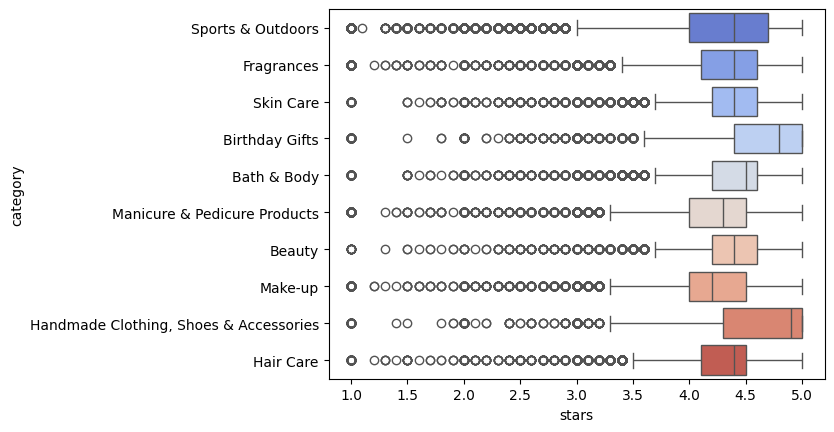

In [29]:
top10_categories = df['category'].value_counts().head(10).index
df_top10 = df[df['category'].isin(top10_categories)]
df_top10 = df_top10[df_top10['stars'] > 0]

sns.boxplot(data=df_top10, y='category', x='stars', palette='coolwarm')

- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [33]:
stars_0 = df[df['stars'] > 0]
median_rating_category = (stars_0.groupby('category')['stars'].median().sort_values(ascending=False))
median_rating_category


category
Handmade Artwork                          5.0
Handmade Baby Products                    5.0
Made in Italy Handmade                    5.0
Snowboards                                5.0
Handmade Clothing, Shoes & Accessories    4.9
                                         ... 
KVM Switches                              4.0
Streaming Clients                         4.0
Action Cameras                            4.0
SIM Cards                                 3.9
Motorbike Instruments                     3.7
Name: stars, Length: 296, dtype: float64

7 categorias del top10 son handmade.

# Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

## 1. Correlation Coefficients:

- Calculate the correlation coefficient between price and stars.

In [ ]:
stars_0 = df[df['stars'] > 0]
correlation_pearson = stars_0['price'].corr(stars_0['stars'], method='pearson')
correlation_pearson

np.float64(-0.004911823000752917)

In [35]:
correlation_spearman = stars_0['price'].corr(stars_0['stars'], method='spearman')
correlation_spearman

np.float64(0.020035042659527897)

- Is there a significant correlation between product price and its rating?

El resultado es casi 0 asi que no tienen relación

## 2. Visualizations:

- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

In [ ]:
stars_0 = df[df['stars'] > 0]

<Axes: xlabel='stars', ylabel='price'>

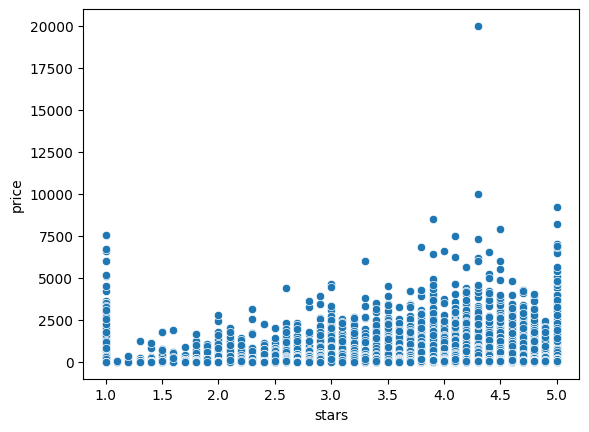

In [37]:
sns.scatterplot(data=stars_0, x='stars', y='price')

- Use a correlation heatmap to visualize correlations between all numerical variables.

<Axes: >

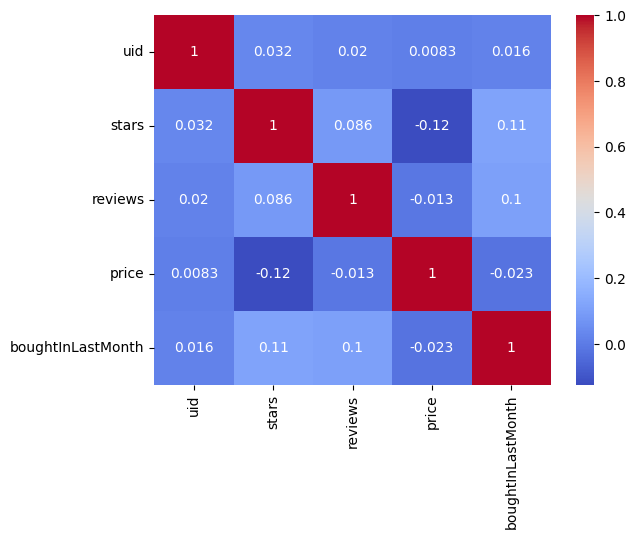

In [50]:
df_num = df.select_dtypes(include= 'number')
correlation_matrix = df_num.corr()

sns.heatmap(correlation_matrix, annot= True, cmap= 'coolwarm')

- Examine if product prices typically follow a normal distribution using a QQ plot.

In [58]:
import statsmodels.api as sm

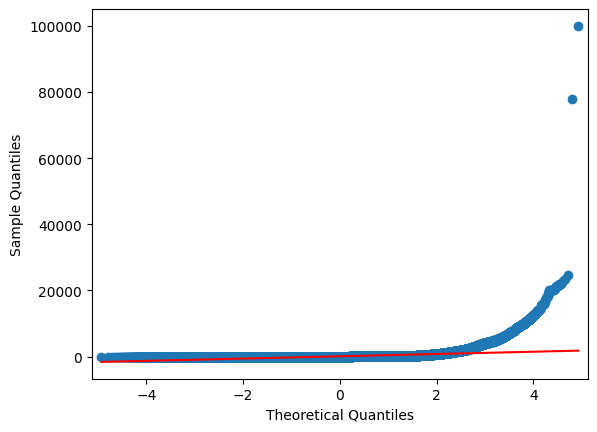

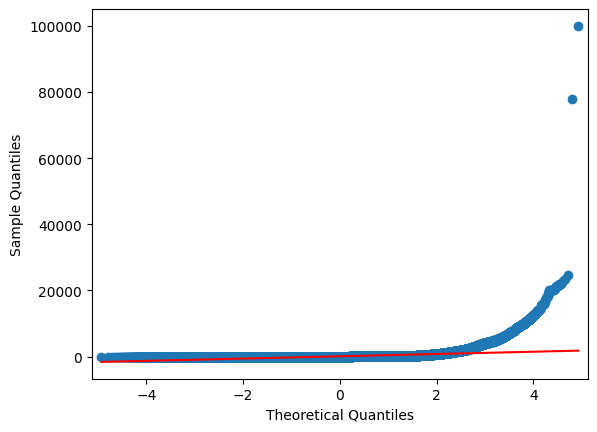

In [65]:
sm.qqplot(df['price'], line= 's')